# TCGA PanCanAtlas RNA-Seq: Die Daten verstehen

**Was steckt in der Datei `EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv`?**

In diesem Notebook geht es nur darum, den Datensatz zu **verstehen**: was eine Zeile und eine Spalte bedeuten, woher die Proben kommen,
wie die Werte entstanden und verteilt sind und welche Auffälligkeiten es gibt.
Eine Forschungsfrage, PCA (*Principal Component Analysis*, Hauptkomponentenanalyse), UMAP (*Uniform Manifold Approximation and Projection*)
und Clustering kommen später. Am Ende steht eine Liste der Entscheidungen, die für die Aufbereitung anstehen.

## Aufbau

1. Hintergrund: Was wird gemessen? Herkunft und Dateien
2. Die Datei laden
3. Die Gene
4. Die Proben: der TCGA-Barcode
5. Klinische Daten und Tumortypen
6. Probentypen: Tumor, Normalgewebe, Metastase
7. Die Werte: Normalisierung, Nullen, Log-Transformation
8. Die Gene über alle Proben: Expression und Streuung
9. Zusammenfassung und Probleme, auf die wir achten müssen

## 1. Hintergrund: Was wird gemessen?

- **TCGA** (*The Cancer Genome Atlas*, „Krebsgenom-Atlas“) ist ein US-amerikanisches Forschungsprogramm (2006–2018), das über 11.000 Tumoren
  aus 33 Krebsarten molekular vermessen hat. Der **PanCanAtlas** (*Pan-Cancer Atlas*) ist die abschließende, gemeinsame Auswertung aller
  Krebsarten von 2018. Dafür wurden die Daten aller Projekte einheitlich aufbereitet; unsere Datei ist die Genexpression daraus.
- **RNA-Seq** (RNA-Sequenzierung; RNA = Ribonukleinsäure) misst, wie viel Boten-RNA (mRNA, *messenger RNA*) jedes Gens in einer Gewebeprobe
  vorhanden ist, also wie **aktiv** ein Gen ist. Die RNA wird in kurze Stücke zerlegt und sequenziert, die Stücke („Reads“) werden den Genen zugeordnet.
- **RSEM** (*RNA-Seq by Expectation-Maximization*) verteilt die Reads auf die Gene (auch Reads, die zu mehreren Genen passen) und schätzt so die Menge pro Gen.
- **RNASeqV2** (RNA-Seq, Version 2) ist die einheitliche Auswertungspipeline der University of North Carolina (UNC).
- **IlluminaHiSeq** ist das Sequenziergerät. Ein Teil der frühen Proben wurde auf dem älteren **Illumina GA** (Genome Analyzer) sequenziert.
- **EBPlusPlusAdjust**: Die Werte sind **batch-korrigiert** mit EB++ (*Empirical Bayes*, erweitert; „PlusPlus“). Damit wurden systematische
  Unterschiede zwischen den Geräten (GA vs. HiSeq) und zwischen Sequenzierzentren herausgerechnet, damit alle Proben vergleichbar sind.
  Das ist eine Weiterentwicklung von ComBat (Johnson et al. 2007), einem Standardverfahren zur Batch-Korrektur. Folgen davon fassen wir in Abschnitt 9 zusammen.

Eine Probe ist hier also ein Stück Gewebe (meist Tumor), beschrieben durch ~20.000 Zahlen: die Aktivität jedes Gens.

### 1.1 Herkunft: GDC PanCanAtlas

Alle drei Dateien stammen von der PanCanAtlas-Seite der GDC (*Genomic Data Commons*) des US-amerikanischen NCI (*National Cancer Institute*):
<https://gdc.cancer.gov/about-data/publications/pancanatlas>. Sie sind frei zugänglich (*Open Access*), ein Login ist nicht nötig.

| Datei | Bereich auf der Seite | Inhalt |
|---|---|---|
| `EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv` | *RNA (Final)* | Genexpression, Gene × Proben, batch-korrigiert |
| `TCGA-CDR-SupplementalTableS1.xlsx` | *TCGA-Clinical Data Resource (CDR) Outcome* | kuratierte klinische Daten pro Patient: Tumortyp, Geschlecht, Alter, Stadium, Überleben |
| `merged_sample_quality_annotations.tsv` | *Merged Sample Quality Annotations* | Qualitätsangaben pro Probe, u. a. welche Proben die PanCanAtlas-Autoren **nicht verwenden** |

Die CDR-Tabelle (*Clinical Data Resource*) stammt aus Liu et al. (2018), *Cell*. Die GDC-Seite empfiehlt ausdrücklich,
sie für klinische Angaben **zuerst** zu verwenden.

Eine ältere, nicht batch-korrigierte Fassung derselben Daten (Stand 2015, nur HiSeq-Proben) liegt auf der Plattform Synapse
(`unc.edu_PANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv`, `syn4311114`). Der bekannte UCI-Datensatz *Gene expression cancer RNA-Seq*
(801 Proben, 5 Tumortypen; UCI = University of California, Irvine) ist ein anonymisierter Ausschnitt daraus.

### 1.2 Die lokalen Dateien

Alles liegt in `data/pancanatlas/` (per `.gitignore` nicht im Repository):

| Datei | Herkunft | Inhalt |
|---|---|---|
| `EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv` | GDC, manueller Download | Originaldaten, 1,9 GB (Gigabyte), Gene × Proben |
| `TCGA-CDR-SupplementalTableS1.xlsx` | GDC, manueller Download | klinische Daten (Excel, mehrere Tabellenblätter) |
| `merged_sample_quality_annotations.tsv` | GDC, manueller Download | Qualitätsangaben |
| `geneExp_samples_x_genes.npy` | erzeugt in Abschnitt 2 | dieselben Werte als Binärdatei, Proben × Gene |
| `geneExp_genes.csv`, `geneExp_samples.csv` | erzeugt in Abschnitt 2 | Gen-IDs bzw. Barcodes in der Reihenfolge der Binärdatei |
| `geneExp_sample_meta.csv`, `geneExp_gene_meta.csv` | erzeugt in Abschnitt 9 | aufbereitete Metadaten zu Proben und Genen für die folgenden Notebooks |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_colwidth", 70)

DATA_DIR = Path("data/pancanatlas")
TSV = DATA_DIR / "EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv"
CDR_XLSX = DATA_DIR / "TCGA-CDR-SupplementalTableS1.xlsx"
QUALITY_TSV = DATA_DIR / "merged_sample_quality_annotations.tsv"
NPY = DATA_DIR / "geneExp_samples_x_genes.npy"          # Cache: Proben × Gene, float32
GENES_CSV = DATA_DIR / "geneExp_genes.csv"
SAMPLES_CSV = DATA_DIR / "geneExp_samples.csv"

## 2. Die Datei laden

Die TSV-Datei (*Tab-Separated Values*, tabulatorgetrennter Text) ist 1,9 GB groß: eine Zeile pro **Gen**, eine Spalte pro **Probe**.
Das Einlesen dauert gut eine Minute. Wir lesen sie deshalb **einmal** ein, drehen sie in die übliche Form **Proben × Gene**
und speichern sie als NumPy-Binärdatei (`float32`, ca. 0,9 GB). Danach lädt sie in Sekunden.

`float32` (32-Bit-Gleitkommazahl) statt `float64` (64-Bit): 7 signifikante Stellen reichen für Messwerte dieser Genauigkeit locker und halbieren den Speicher.

In [2]:
if not NPY.exists():
    df = pd.read_csv(TSV, sep="\t", index_col=0, engine="pyarrow")
    np.save(NPY, df.to_numpy(np.float32).T)
    pd.Series(df.index, name="gene_id").to_csv(GENES_CSV, index=False)
    pd.Series(df.columns, name="barcode").to_csv(SAMPLES_CSV, index=False)
    del df

X = np.load(NPY)
gene_id = pd.read_csv(GENES_CSV)["gene_id"]
barcode = pd.read_csv(SAMPLES_CSV)["barcode"]
n, p = X.shape
nan = np.isnan(X)
print(f"{n} Proben × {p} Gene, {X.nbytes / 1e9:.2f} GB im Speicher")
print(f"Fehlende Werte (NaN): {nan.sum():,} ({nan.mean():.1%}) | negative Werte: {(X < 0).sum():,}")
print("Doppelte Proben-IDs:", barcode.duplicated().sum(), "| doppelte Gen-IDs:", gene_id.duplicated().sum())
print("\nAusschnitt: Zeilen = Proben (Barcode), Spalten = Gene")
pd.DataFrame(X[:4, 1000:1005], index=barcode[:4].to_numpy(), columns=gene_id[1000:1005].to_numpy())

11069 Proben × 20531 Gene, 0.91 GB im Speicher


Fehlende Werte (NaN): 3,973,192 (1.7%) | negative Werte: 1,250,289
Doppelte Proben-IDs: 0 | doppelte Gen-IDs: 0

Ausschnitt: Zeilen = Proben (Barcode), Spalten = Gene


,ARL17B|641522,ARL2|402,ARL2BP|23568,ARL3|403,ARL4A|10124
TCGA-OR-A5J1-01A-11R-A29S-07,0.0000,3084.530029,3005.760010,1168.589966,182.035995
TCGA-OR-A5J2-01A-11R-A29S-07,1.3287,1678.569946,1478.459961,1511.469971,211.380997
TCGA-OR-A5J3-01A-11R-A29S-07,2.8085,905.346985,3729.229980,572.359985,517.848999
TCGA-OR-A5J5-01A-11R-A29S-07,3.3695,1172.729980,2858.250000,493.415985,299.768005


**Beobachtung:** Anders als bei Rohdaten gibt es hier **fehlende Werte** (NaN, *Not a Number*) und **negative Werte**,
obwohl eine Expression nicht negativ sein kann. Beides ist eine Folge der Batch-Korrektur (siehe Abschnitt 9).
Die Matrix ist **breit**: Es gibt fast doppelt so viele Gene wie Proben ($p \approx 2n$).
Das ist die typische Situation, für die Dimensionsreduktion gedacht ist.

## 3. Die Gene

Jede Gen-ID (Identifikationsnummer) hat die Form `Symbol|Entrez-ID`, z. B. `TP53|7157` (TP53 = Tumorprotein p53).
Das Symbol ist der übliche Kurzname des Gens, die Entrez-ID die eindeutige Nummer in der Datenbank des NCBI (*National Center for Biotechnology Information*).

In [3]:
gsplit = gene_id.str.split("|", expand=True)
genes = pd.DataFrame({"gene_id": gene_id, "symbol": gsplit[0], "entrez": gsplit[1].astype(int)})
no_sym = genes["symbol"] == "?"
dup_sym = genes["symbol"].duplicated(keep=False) & ~no_sym
print("Gene ohne Symbol ('?'):", no_sym.sum())
print("Symbole, die mehrfach vorkommen:", genes.loc[dup_sym, "symbol"].unique().tolist())
print("Entrez-IDs eindeutig:", genes["entrez"].is_unique)
genes[no_sym].head(4)

Gene ohne Symbol ('?'): 29
Symbole, die mehrfach vorkommen: ['SLC35E2']
Entrez-IDs eindeutig: True


,gene_id,symbol,entrez
0,?|100130426,?,100130426
1,?|100133144,?,100133144
2,?|100134869,?,100134869
3,?|10357,?,10357


**Beobachtung:** 29 Gene haben kein Symbol, nur eine Entrez-ID. Das sind Einträge, die zum Zeitpunkt der Annotation (Stand ca. 2009)
noch keinen offiziellen Namen hatten. Ein Symbol (`SLC35E2`, *Solute Carrier Family 35 Member E2*, ein Membrantransporter) kommt doppelt vor,
mit zwei verschiedenen Entrez-IDs. Für lesbare Namen nehmen wir das Symbol und hängen nur in diesen Sonderfällen die Entrez-ID an.
Wegen des Annotationsstands heißen manche Gene noch anders als heute (z. B. `SILV` statt `PMEL`).

### 3.1 Einige Beispielgene

Damit die Gene greifbarer werden, ein paar Beispiele, die uns später wieder begegnen:

| Gensymbol | ausgeschrieben | Rolle | erwartetes Muster |
|---|---|---|---|
| `GAPDH` | Glycerinaldehyd-3-phosphat-Dehydrogenase | Zuckerstoffwechsel | **Haushaltsgen**: in jeder Zelle hoch, kaum Unterschiede |
| `ACTB` | Beta-Aktin | Zellgerüst | Haushaltsgen |
| `ALB` | Albumin | Bluteiweiß, wird in der Leber gebildet | nur in Lebergewebe hoch |
| `KRT5` | Keratin 5 | Strukturprotein von Plattenepithel (Haut, Schleimhaut) | hoch in Plattenepithelkarzinomen |
| `ESR1` | Östrogenrezeptor 1 | Andockstelle für das Hormon Östrogen | hoch in hormonabhängigen Geweben (Brust, Gebärmutter) |
| `XIST` | *X-inactive specific transcript* | schaltet eines der beiden X-Chromosomen ab | nur in weiblichen Zellen aktiv |
| `RPS4Y1` | ribosomales Protein S4, Y-chromosomal | Baustein der Ribosomen, liegt auf dem Y-Chromosom | nur in männlichen Zellen aktiv |

In [4]:
genes["name"] = np.where(no_sym | dup_sym, genes["symbol"] + "|" + genes["entrez"].astype(str), genes["symbol"])
assert genes["name"].is_unique
gidx = pd.Series(np.arange(p), index=genes["name"])   # Name -> Spalte

examples = ["GAPDH", "ACTB", "ALB", "KRT5", "ESR1", "XIST", "RPS4Y1"]
pd.DataFrame(X[:5, gidx[examples].to_numpy()], index=barcode[:5].to_numpy(), columns=examples).round(1)

,GAPDH,ACTB,ALB,KRT5,ESR1,XIST,RPS4Y1
TCGA-OR-A5J1-01A-11R-A29S-07,57986.101562,68807.398438,1.400000,0.0,177.199997,0.500000,7013.899902
TCGA-OR-A5J2-01A-11R-A29S-07,45122.800781,71065.101562,5.200000,0.8,34.599998,7993.000000,5.200000
TCGA-OR-A5J3-01A-11R-A29S-07,270999.000000,73505.000000,5.300000,1.2,6.500000,194.600006,5.300000
TCGA-OR-A5J5-01A-11R-A29S-07,127711.000000,111056.000000,312.899994,0.0,30.200001,0.000000,6802.500000
TCGA-OR-A5J6-01A-31R-A29S-07,45653.000000,52458.199219,1.100000,0.0,46.900002,2109.100098,1.100000


**Beobachtung:** Schon in den ersten fünf Proben (alle aus ACC, Nebennierenrindenkarzinom) sieht man die Muster: `GAPDH` und `ACTB` liegen bei
Zehn- bis Hunderttausenden, `ALB` und `KRT5` sind meist nahe 0 (keine Leber, kein Plattenepithel; eine Probe hat etwas `ALB`). `XIST` und `RPS4Y1` schließen sich aus:
Hoch ist jeweils nur eines von beiden, je nach Geschlecht des Patienten.

## 4. Die Proben: der TCGA-Barcode

Die Spaltennamen sind **TCGA-Barcodes**. Sie enthalten die gesamte Herkunft einer Probe:

`TCGA-OR-A5J1-01A-11R-A29S-07`

| Teil | Beispiel | Bedeutung |
|---|---|---|
| Projekt | `TCGA` | immer TCGA (The Cancer Genome Atlas) |
| TSS (*Tissue Source Site*) | `OR` | Klinik, die die Probe geliefert hat |
| Teilnehmer | `A5J1` | Patient (zusammen mit TSS eindeutig; `TCGA-OR-A5J1` ist die Patienten-ID) |
| Probentyp | `01` | `01` Primärtumor, `11` Normalgewebe, `06` Metastase … |
| Vial | `A` | Reihenfolge der Gewebeproben desselben Typs |
| Portion | `11` | Teilstück der Probe |
| Analyt | `R` | `R` = RNA (Ribonukleinsäure), `T` = Gesamt-RNA (*total RNA*, nur bei Leukämie) |
| Plate | `A29S` | Platte, auf der die Proben gemeinsam verarbeitet wurden (**Batch**) |
| Center | `07` | Zentrum, das die Probe erhalten hat (`07` = UNC, University of North Carolina) |

Wir zerlegen alle Barcodes in eine Metadaten-Tabelle.

In [5]:
parts = barcode.str.split("-", expand=True)
meta = pd.DataFrame({
    "barcode": barcode,
    "patient": parts[0] + "-" + parts[1] + "-" + parts[2],
    "tss": parts[1],
    "sample_type": parts[3].str[:2],
    "vial": parts[3].str[2],
    "portion": parts[4].str[:2],
    "analyte": parts[4].str[2],
    "plate": parts[5],
    "center": parts[6],
})
print("Analyt:", meta["analyte"].value_counts().to_dict())
print("Patienten:", meta["patient"].nunique(), "| Kliniken (TSS):", meta["tss"].nunique(),
      "| Platten:", meta["plate"].nunique(), "| Center:", meta["center"].value_counts().to_dict())
meta.head()

Analyt: {'R': 10896, 'T': 173}
Patienten: 10274 | Kliniken (TSS): 713 | Platten: 241 | Center: {'07': 9772, '13': 719, '31': 409, '01': 169}


,barcode,patient,tss,sample_type,vial,portion,analyte,plate,center
0,TCGA-OR-A5J1-01A-11R-A29S-07,TCGA-OR-A5J1,OR,01,A,11,R,A29S,07
1,TCGA-OR-A5J2-01A-11R-A29S-07,TCGA-OR-A5J2,OR,01,A,11,R,A29S,07
2,TCGA-OR-A5J3-01A-11R-A29S-07,TCGA-OR-A5J3,OR,01,A,11,R,A29S,07
3,TCGA-OR-A5J5-01A-11R-A29S-07,TCGA-OR-A5J5,OR,01,A,11,R,A29S,07
4,TCGA-OR-A5J6-01A-31R-A29S-07,TCGA-OR-A5J6,OR,01,A,31,R,A29S,07


## 5. Klinische Daten und Tumortypen

Der Tumortyp steht nicht in der Expressionsdatei. Wir holen ihn aus der **CDR-Tabelle** (*Clinical Data Resource*): eine Zeile pro Patient,
mit Tumortyp (`type`), Geschlecht, Alter, Stadium und Überlebensdaten. Die Excel-Datei hat mehrere Tabellenblätter; wir brauchen `TCGA-CDR`.

Für Proben, deren Patient nicht in der CDR-Tabelle steht, nehmen wir den Tumortyp aus der Qualitätsdatei (Spalte `cancer type`).
Aus der Qualitätsdatei holen wir außerdem das **Sequenziergerät** (HiSeq oder GA) jeder Probe.

In [6]:
cdr = pd.read_excel(CDR_XLSX, sheet_name="TCGA-CDR").drop(columns="Unnamed: 0").set_index("bcr_patient_barcode")
assert cdr.index.is_unique

quality = pd.read_csv(QUALITY_TSV, sep="\t")
rna_q = (quality[quality["platform"].isin(["IlluminaHiSeq_RNASeqV2", "IlluminaGA_RNASeqV2"])]
         .sort_values("platform", ascending=False)        # wenige Aliquots stehen bei beiden Geräten: HiSeq bevorzugen
         .drop_duplicates("aliquot_barcode")
         .set_index("aliquot_barcode")
         .reindex(barcode))

print("Patienten in der CDR-Tabelle:", len(cdr), "| Proben, deren Patient fehlt:", (~meta["patient"].isin(cdr.index)).sum())
print("Proben ohne Eintrag in der Qualitätsdatei:", rna_q["platform"].isna().sum())

meta["study"] = meta["patient"].map(cdr["type"]).fillna(rna_q["cancer type"].reset_index(drop=True))
both = meta["patient"].map(cdr["type"]).notna() & rna_q["cancer type"].notna().to_numpy()
print("Widersprüche Tumortyp CDR vs. Qualitätsdatei:", (meta.loc[both, "study"].to_numpy() != rna_q.loc[both.to_numpy(), "cancer type"].to_numpy()).sum())
print("Proben ohne Tumortyp:", meta["study"].isna().sum(), "| Anzahl Tumortypen:", meta["study"].nunique())

PLATFORM = {"IlluminaHiSeq_RNASeqV2": "HiSeq", "IlluminaGA_RNASeqV2": "GA"}
meta["platform"] = rna_q["platform"].map(PLATFORM).fillna("ohne Angabe").to_numpy()
meta["gender"] = meta["patient"].map(cdr["gender"]).map({"FEMALE": "weiblich", "MALE": "männlich"})
meta["age"] = meta["patient"].map(cdr["age_at_initial_pathologic_diagnosis"])
meta["do_not_use"] = rna_q["Do_not_use"].to_numpy()
print("Gerät:", meta["platform"].value_counts().to_dict())

Patienten in der CDR-Tabelle: 11160 | Proben, deren Patient fehlt: 46
Proben ohne Eintrag in der Qualitätsdatei: 33
Widersprüche Tumortyp CDR vs. Qualitätsdatei: 0
Proben ohne Tumortyp: 0 | Anzahl Tumortypen: 33
Gerät: {'HiSeq': 10438, 'GA': 598, 'ohne Angabe': 33}


In [7]:
STUDY = {  # Kürzel: (deutsch, offizieller englischer Studienname)
    "ACC": ("Nebennierenrindenkarzinom", "Adrenocortical carcinoma"),
    "BLCA": ("Harnblasenkarzinom (Urothel)", "Bladder Urothelial Carcinoma"),
    "BRCA": ("Brustkrebs (invasives Mammakarzinom)", "Breast invasive carcinoma"),
    "CESC": ("Gebärmutterhalskrebs (Plattenepithel- und Adenokarzinom)", "Cervical squamous cell carcinoma and endocervical adenocarcinoma"),
    "CHOL": ("Gallengangkrebs (Cholangiokarzinom)", "Cholangiocarcinoma"),
    "COAD": ("Dickdarmkrebs (Adenokarzinom des Kolons)", "Colon adenocarcinoma"),
    "DLBC": ("diffus großzelliges B-Zell-Lymphom", "Lymphoid Neoplasm Diffuse Large B-cell Lymphoma"),
    "ESCA": ("Speiseröhrenkrebs (Ösophaguskarzinom)", "Esophageal carcinoma"),
    "GBM": ("Glioblastom (bösartigster Hirntumor)", "Glioblastoma multiforme"),
    "HNSC": ("Plattenepithelkarzinom von Kopf und Hals", "Head and Neck squamous cell carcinoma"),
    "KICH": ("chromophobes Nierenzellkarzinom", "Kidney Chromophobe"),
    "KIRC": ("klarzelliges Nierenzellkarzinom", "Kidney renal clear cell carcinoma"),
    "KIRP": ("papilläres Nierenzellkarzinom", "Kidney renal papillary cell carcinoma"),
    "LAML": ("akute myeloische Leukämie", "Acute Myeloid Leukemia"),
    "LGG": ("niedriggradiges Gliom (Hirntumor)", "Brain Lower Grade Glioma"),
    "LIHC": ("Leberzellkarzinom", "Liver hepatocellular carcinoma"),
    "LUAD": ("Adenokarzinom der Lunge", "Lung adenocarcinoma"),
    "LUSC": ("Plattenepithelkarzinom der Lunge", "Lung squamous cell carcinoma"),
    "MESO": ("Mesotheliom (Brust-/Bauchfell)", "Mesothelioma"),
    "OV": ("seröses Ovarialkarzinom (Eierstock)", "Ovarian serous cystadenocarcinoma"),
    "PAAD": ("Bauchspeicheldrüsenkrebs (Adenokarzinom)", "Pancreatic adenocarcinoma"),
    "PCPG": ("Phäochromozytom und Paragangliom", "Pheochromocytoma and Paraganglioma"),
    "PRAD": ("Prostatakrebs (Adenokarzinom)", "Prostate adenocarcinoma"),
    "READ": ("Mastdarmkrebs (Adenokarzinom des Rektums)", "Rectum adenocarcinoma"),
    "SARC": ("Sarkom (Weichteiltumor)", "Sarcoma"),
    "SKCM": ("Melanom der Haut", "Skin Cutaneous Melanoma"),
    "STAD": ("Magenkrebs (Adenokarzinom)", "Stomach adenocarcinoma"),
    "TGCT": ("Keimzelltumoren des Hodens", "Testicular Germ Cell Tumors"),
    "THCA": ("Schilddrüsenkarzinom", "Thyroid carcinoma"),
    "THYM": ("Thymom (Thymusdrüse)", "Thymoma"),
    "UCEC": ("Gebärmutterkörperkrebs (Endometriumkarzinom)", "Uterine Corpus Endometrial Carcinoma"),
    "UCS": ("Karzinosarkom der Gebärmutter", "Uterine Carcinosarcoma"),
    "UVM": ("Aderhautmelanom (Auge)", "Uveal Melanoma"),
}
assert set(meta["study"]) == set(STUDY)

counts = meta["study"].value_counts()
tab = pd.DataFrame(STUDY, index=["Tumortyp (deutsch)", "Studienname (englisch, offiziell)"]).T.loc[counts.index]
tab.insert(0, "Proben", counts)
tab.index.name = "Kürzel"
tab

,Proben,Tumortyp (deutsch),"Studienname (englisch, offiziell)"
Kürzel,,,
BRCA,1218,Brustkrebs (invasives Mammakarzinom),Breast invasive carcinoma
KIRC,606,klarzelliges Nierenzellkarzinom,Kidney renal clear cell carcinoma
LUAD,576,Adenokarzinom der Lunge,Lung adenocarcinoma
THCA,572,Schilddrüsenkarzinom,Thyroid carcinoma
UCEC,567,Gebärmutterkörperkrebs (Endometriumkarzinom),Uterine Corpus Endometrial Carcinoma
HNSC,566,Plattenepithelkarzinom von Kopf und Hals,Head and Neck squamous cell carcinoma
LUSC,554,Plattenepithelkarzinom der Lunge,Lung squamous cell carcinoma
PRAD,550,Prostatakrebs (Adenokarzinom),Prostate adenocarcinoma
LGG,534,niedriggradiges Gliom (Hirntumor),Brain Lower Grade Glioma


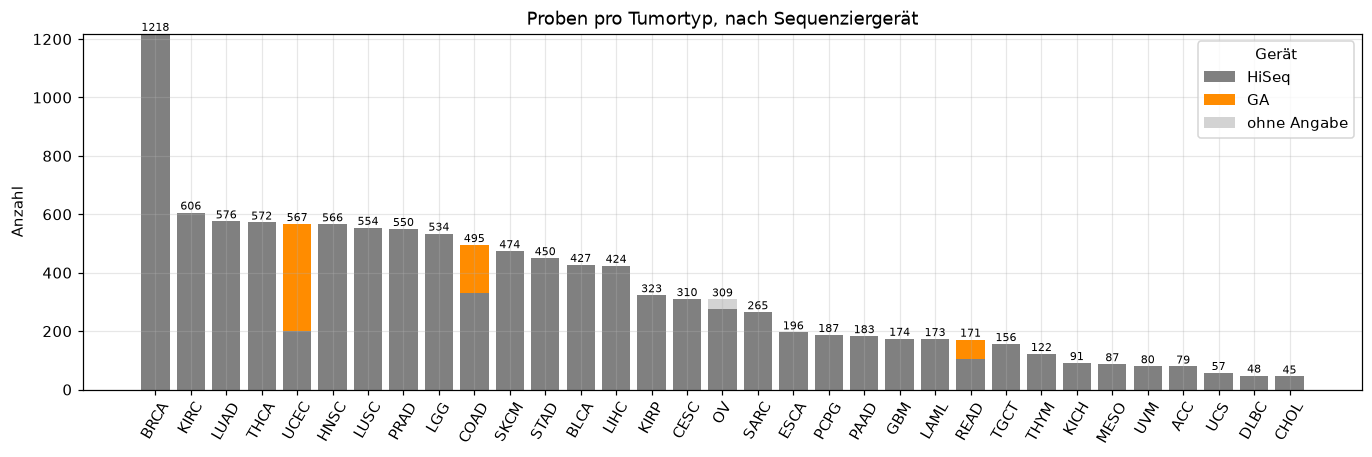

Tumortypen mit GA-Proben: {'UCEC': 366, 'COAD': 166, 'READ': 66}


In [8]:
ct = pd.crosstab(meta["study"], meta["platform"]).loc[counts.index]
fig, ax = plt.subplots(figsize=(15, 4.2))
bottom = np.zeros(len(ct))
for col, c in zip(["HiSeq", "GA", "ohne Angabe"], ["gray", "darkorange", "lightgray"]):
    if col in ct:
        ax.bar(ct.index, ct[col], bottom=bottom, color=c, label=col)
        bottom += ct[col].to_numpy()
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center", fontsize=7)
ax.set(title="Proben pro Tumortyp, nach Sequenziergerät", ylabel="Anzahl")
ax.tick_params(axis="x", rotation=60)
ax.legend(title="Gerät")
plt.show()
print("Tumortypen mit GA-Proben:", ct.loc[ct.get("GA", 0) > 0, "GA"].to_dict())

**Beobachtungen:**
- Alle Proben haben einen Tumortyp: **33 Tumortypen**, die komplette TCGA-Sammlung. CDR-Tabelle und Qualitätsdatei widersprechen sich nicht.
- Die Gruppen sind **sehr ungleich groß**: BRCA (Brustkrebs) hat über 1.200 Proben, DLBC (diffus großzelliges B-Zell-Lymphom)
  und CHOL (Gallengangkrebs) unter 50. In jeder Analyse ohne Gewichtung zählt Brustkrebs 25-mal so viel wie Gallengangkrebs.
- **GA-Proben** (ältere Geräte) gibt es nur bei COAD (Dickdarmkrebs), READ (Mastdarmkrebs) und UCEC (Gebärmutterkörperkrebs).
  Bei diesen drei Typen stammt ein großer Teil der Proben vom alten Gerät. Die Batch-Korrektur soll diesen Unterschied ausgleichen.
- Einige Tumortypen sind **biologisch eng verwandt**: Niere (KIRC klarzellig, KIRP papillär, KICH chromophob), Gehirn (LGG niedriggradiges Gliom,
  GBM Glioblastom), Darm (COAD, READ), Plattenepithelkarzinome (LUSC Lunge, HNSC Kopf-Hals, Teile von CESC Gebärmutterhals und ESCA Speiseröhre),
  Gebärmutter (UCEC, UCS Karzinosarkom), Melanome (SKCM Haut, UVM Auge). Das sollte man bei jeder späteren Interpretation im Kopf haben.

## 6. Probentypen: Tumor, Normalgewebe, Metastase

sample_type_name
Primärtumor                 9706
Normalgewebe                 737
Metastase                    395
Primärtumor (Blut)           173
Rezidiv                       46
Primärtumor (zusätzlich)      11
Metastase (zusätzlich)         1


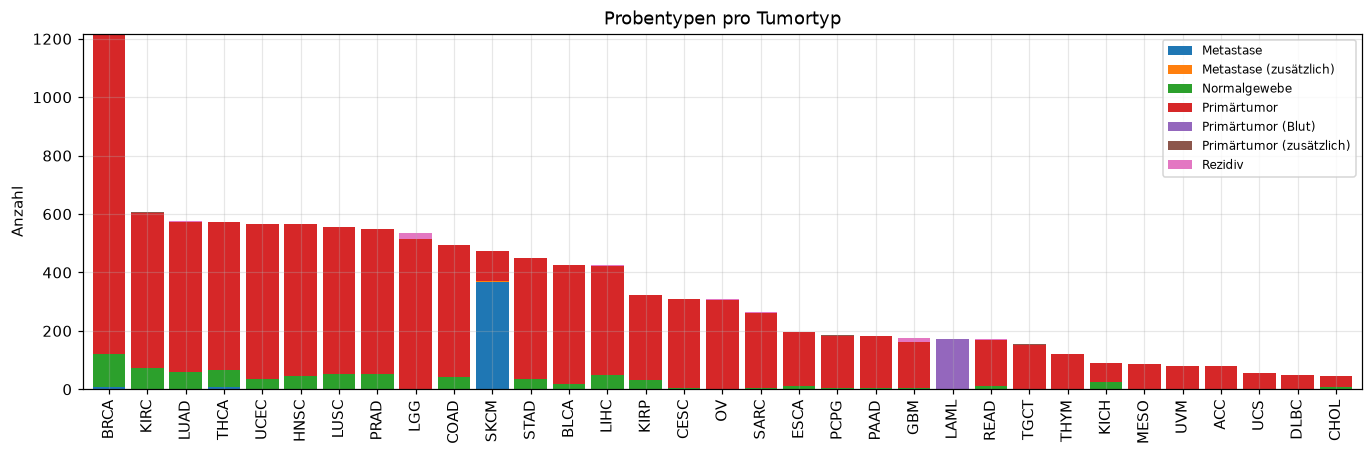

In [9]:
SAMPLE_TYPES = {"01": "Primärtumor", "02": "Rezidiv", "03": "Primärtumor (Blut)", "05": "Primärtumor (zusätzlich)",
                "06": "Metastase", "07": "Metastase (zusätzlich)", "11": "Normalgewebe"}
meta["sample_type_name"] = meta["sample_type"].map(SAMPLE_TYPES)
print(meta["sample_type_name"].value_counts().to_string())

ct = pd.crosstab(meta["study"], meta["sample_type_name"]).loc[counts.index]
fig, ax = plt.subplots(figsize=(15, 4.2))
ct.plot.bar(stacked=True, ax=ax, width=0.85, color=plt.cm.tab10.colors)
ax.set(title="Probentypen pro Tumortyp", xlabel="", ylabel="Anzahl")
ax.legend(fontsize=8)
plt.show()

**Beobachtungen:**
- Der Großteil sind **Primärtumoren** (`01`). Bei Leukämie (LAML, akute myeloische Leukämie) gibt es kein festes Gewebe, dort heißt der Primärtumor `03` (Blut).
- **Hautkrebs (SKCM, *Skin Cutaneous Melanoma*, Melanom der Haut) besteht überwiegend aus Metastasen** (`06`):
  Melanome werden oft erst operiert, wenn sie gestreut haben. Diese Proben stammen aus Lymphknoten oder anderen Organen und enthalten deren Gewebe mit.
- **Normalgewebe** (`11`) gibt es für viele, aber nicht alle Tumortypen, meist von denselben Patienten wie der Tumor.

In [10]:
per_patient = meta.groupby("patient").size()
print("Patienten mit mehr als einer Probe:", (per_patient > 1).sum())
combos = meta.groupby("patient")["sample_type"].apply(lambda s: "+".join(sorted(s))).loc[per_patient[per_patient > 1].index]
print(combos.value_counts().head(8).to_string())
tumor_dup = meta[meta["sample_type"].isin(["01", "03"])].groupby("patient").size()
print("Patienten mit mehreren Primärtumor-Proben:", (tumor_dup > 1).sum())

Patienten mit mehr als einer Probe: 785
sample_type
01+11       709
01+02        27
01+06        24
01+05        10
01+02+02      5
01+01         3
01+06+11      3
01+01+02      1
Patienten mit mehreren Primärtumor-Proben: 4


**Beobachtung:** Die meisten Mehrfachproben sind Paare aus **Tumor und Normalgewebe** desselben Patienten.
Daneben gibt es Primärtumor plus Rezidiv (`02`), plus Metastase (`06`) oder plus zusätzlichen Primärtumor (`05`).
Wer „eine Probe pro Patient“ will, muss hier eine Regel festlegen.

## 7. Die Werte: Normalisierung, Nullen, Log-Transformation

Vor der Batch-Korrektur waren die Werte **upper-quartile-normalisierte RSEM-Werte**: TCGA hat jede Probe so skaliert, dass das
**obere Quartil der von null verschiedenen Werte 1.000** ist. Das gleicht unterschiedliche Sequenziertiefen zwischen Proben aus. Wie sieht das jetzt aus?

Für alle Darstellungen setzen wir die **negativen Werte auf 0** (sie sind ein Artefakt der Batch-Korrektur, siehe Abschnitt 9)
und lassen **fehlende Werte** stehen; sie werden in den Statistiken übersprungen.

In [11]:
X0 = np.clip(X, 0, None)          # negative Werte -> 0, NaN bleibt NaN
nan_per_gene = nan.sum(axis=0)
Xnz = np.where(X0 > 0, X0, np.nan)
meta["upper_quartile"] = np.nanpercentile(Xnz, 75, axis=1)
del Xnz
print(f"Wertebereich: [{np.nanmin(X):.2f}, {np.nanmax(X):,.0f}]")
print(f"Anteil exakter Nullen (nach Abschneiden): {np.nanmean(X0 == 0):.1%}")
print(f"Proben mit oberem Quartil zwischen 990 und 1.010: {meta['upper_quartile'].between(990, 1010).mean():.0%}")
meta.groupby("platform")["upper_quartile"].describe()[["count", "min", "50%", "max"]].round(1)

Wertebereich: [-0.99, 9,924,360]
Anteil exakter Nullen (nach Abschneiden): 12.9%
Proben mit oberem Quartil zwischen 990 und 1.010: 86%


,count,min,50%,max
platform,,,,
GA,598.0,776.9,1039.1,1126.1
HiSeq,10438.0,906.9,999.8,1111.1
ohne Angabe,33.0,946.8,964.0,985.0


**Beobachtung:** Bei 86 % der Proben liegt das obere Quartil weiterhin bei ≈ 1.000: Das sind die Proben, die EB++ nicht verändert hat.
Bei den korrigierten Proben (GA-Gerät, andere Zentren; „ohne Angabe“ sind 33 OV-Proben ohne Eintrag in der Qualitätsdatei) weicht es ab,
weil EB++ die Werte gen-weise verschoben und gestreckt hat. Die Proben sind also nicht mehr exakt gleich normiert, aber vergleichbar.
Die Werte reichen von 0 bis fast 10 Millionen; gut jeder zehnte Eintrag ist 0 (Gen in dieser Probe nicht nachgewiesen).

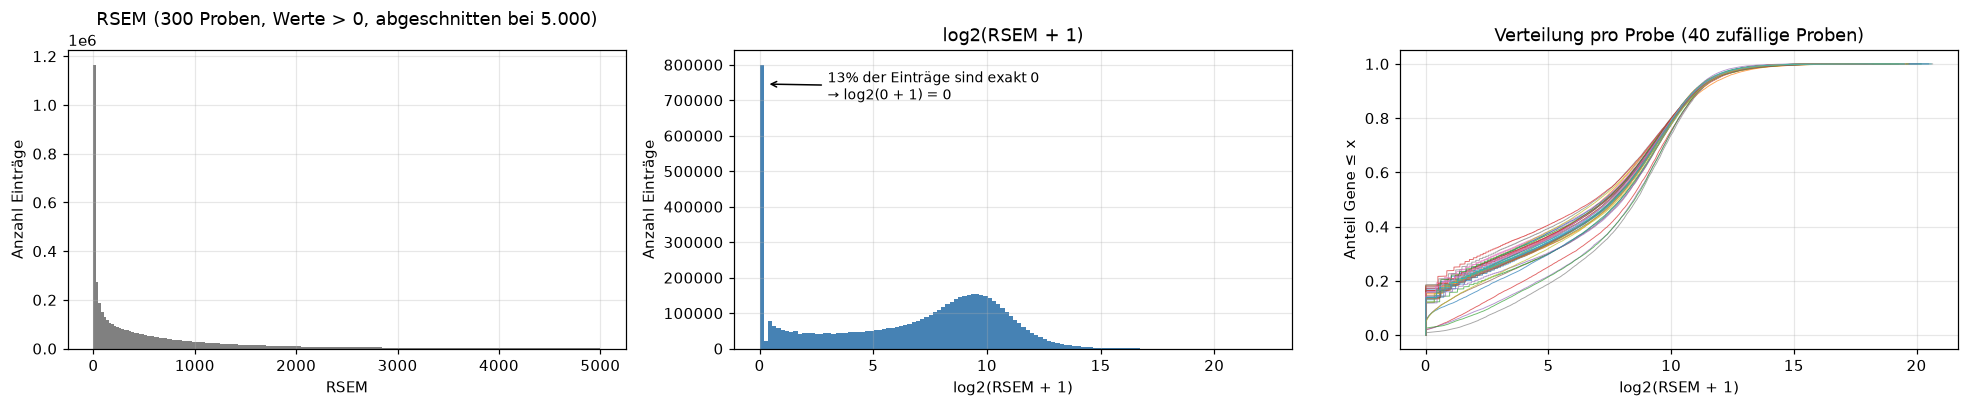

Schiefe RSEM: 217.3 | Schiefe log2(RSEM+1): -0.36


In [12]:
rng = np.random.default_rng(0)
vals = X0[rng.choice(n, 300, replace=False)].ravel()
vals = vals[~np.isnan(vals)]
L = np.log2(X0 + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
axes[0].hist(vals[vals > 0], bins=200, color="gray", range=(0, 5000))
axes[0].set(title="RSEM (300 Proben, Werte > 0, abgeschnitten bei 5.000)", xlabel="RSEM", ylabel="Anzahl Einträge")
axes[1].hist(np.log2(vals + 1), bins=120, color="steelblue")
zero_share = (vals == 0).mean()
axes[1].annotate(f"{zero_share:.0%} der Einträge sind exakt 0\n→ log2(0 + 1) = 0", (0.3, (vals == 0).sum() * 0.95),
                 xytext=(40, -10), textcoords="offset points", fontsize=9, arrowprops={"arrowstyle": "->"})
axes[1].set(title="log2(RSEM + 1)", xlabel="log2(RSEM + 1)", ylabel="Anzahl Einträge")
for i in rng.choice(n, 40, replace=False):
    d = np.sort(L[i][~np.isnan(L[i])])
    axes[2].plot(d, np.linspace(0, 1, len(d)), lw=0.6, alpha=0.7)
axes[2].set(title="Verteilung pro Probe (40 zufällige Proben)", xlabel="log2(RSEM + 1)", ylabel="Anteil Gene ≤ x")
plt.tight_layout()
plt.show()
print(f"Schiefe RSEM: {stats.skew(vals):.1f} | Schiefe log2(RSEM+1): {stats.skew(np.log2(vals + 1)):.2f}")

**Beobachtungen:**
- Auf der Originalskala ist die Verteilung extrem **rechtsschief**: Wenige Gene sind millionenfach exprimiert, die meisten kaum.
  Ohne Transformation würden diese wenigen Gene jede Varianz- und Abstandsberechnung bestimmen.
- Nach $\log_2(x + 1)$ sieht man zwei Gipfel. **Der hohe Balken bei 0 ist kein großer Wert, sondern eine große Anzahl:** Ein Wert von 0
  wird zu $\log_2(0 + 1) = \log_2(1) = 0$, und weil gut jeder zehnte Eintrag exakt 0 ist, landen sehr viele Einträge im selben Balken.
  Die y-Achse zählt Einträge. Der zweite, breite Gipfel um 9–10 (also RSEM ≈ 500–1.000) sind die exprimierten Gene.
- Ein Unterschied von 1 bedeutet nun eine **Verdopplung** der Expression. Das „+1“ verhindert $\log(0)$, das nicht definiert ist.
- Die Verteilungen der einzelnen Proben liegen eng übereinander, eine Folge der Normalisierung. Einzelne Proben weichen ab (mehr Nullen):

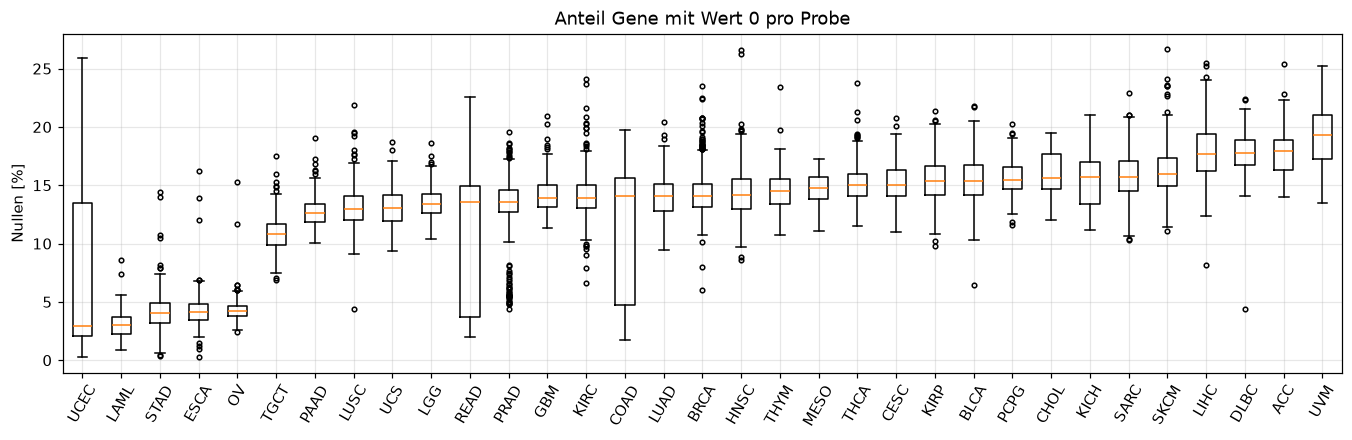

,barcode,study,sample_type_name,platform,center,zero_frac
805,TCGA-D3-A2JK-06A-11R-A18S-07,SKCM,Metastase,HiSeq,07,0.266670
1599,TCGA-CV-A45Q-01A-11R-A24H-07,HNSC,Primärtumor,HiSeq,07,0.265939
1649,TCGA-D6-A6ES-01A-12R-A31N-07,HNSC,Primärtumor,HiSeq,07,0.262384
659,TCGA-BS-A0V4-01A-11R-A14D-07,UCEC,Primärtumor,HiSeq,07,0.259218
5305,TCGA-FV-A4ZP-01A-12R-A266-07,LIHC,Primärtumor,HiSeq,07,0.254737
53,TCGA-OR-A5L9-01A-11R-A29S-07,ACC,Primärtumor,HiSeq,07,0.253616


In [13]:
meta["zero_frac"] = np.nanmean(X0 == 0, axis=1)
fig, ax = plt.subplots(figsize=(15, 4))
order = meta.groupby("study")["zero_frac"].median().sort_values().index
ax.boxplot([meta.loc[meta["study"] == s, "zero_frac"] * 100 for s in order], tick_labels=order, showfliers=True,
           flierprops={"markersize": 3})
ax.set(title="Anteil Gene mit Wert 0 pro Probe", ylabel="Nullen [%]")
ax.tick_params(axis="x", rotation=60)
plt.show()
meta.sort_values("zero_frac", ascending=False)[["barcode", "study", "sample_type_name", "platform", "center", "zero_frac"]].head(6)

**Beobachtungen:**
- Der Anteil der Nullen hängt vom **Tumortyp** ab. Das ist teils Biologie: Blutzellen (LAML akute myeloische Leukämie, DLBC Lymphom) nutzen ein engeres
  Genprogramm, Keimzelltumoren (TGCT, Hodenkrebs) haben ungewöhnlich viele Gene aktiv. Teils ist es Technik (RNA-Qualität, Sequenziertiefe)
  und, seit der Korrektur, auch das Abschneiden negativer Werte auf 0 in den korrigierten Proben.
- Einzelne Proben haben auffällig viele Nullen. Das können Proben mit schlechter RNA-Qualität sein. **Kandidaten für einen Qualitätsfilter** (siehe Abschnitt 9).

## 8. Die Gene über alle Proben: Expression und Streuung

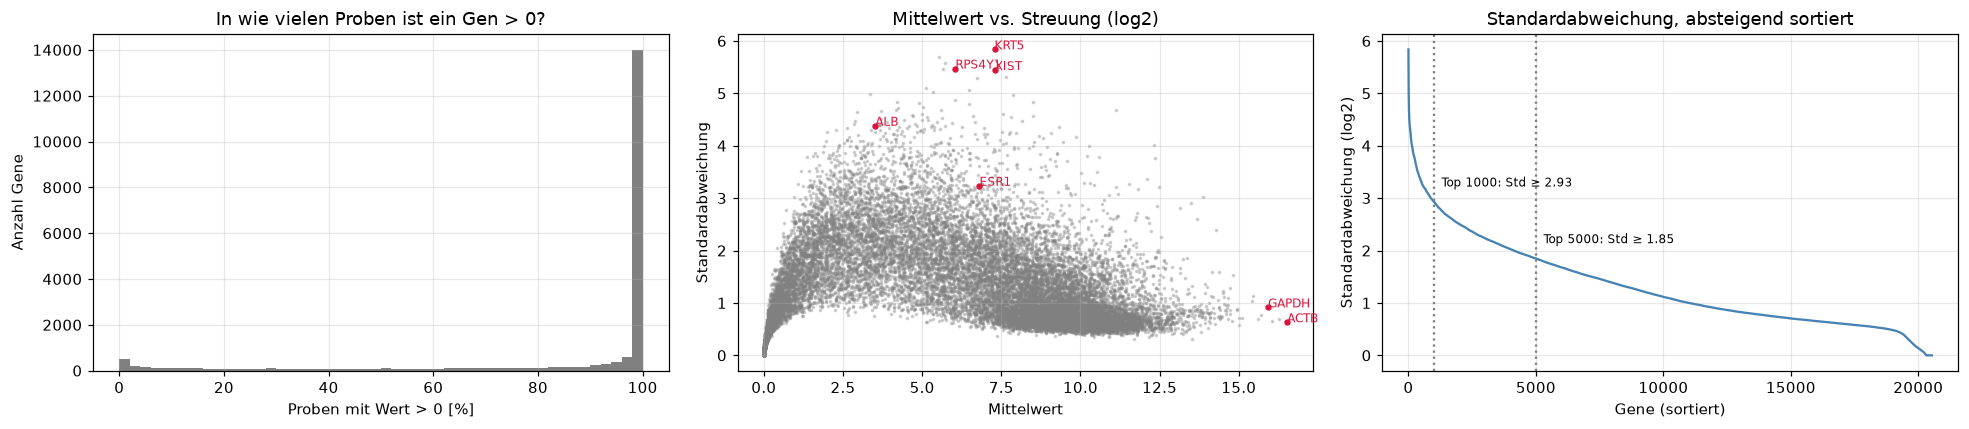

Gene, die in keiner Probe > 0 sind: 219
Gene, die in < 10 % der Proben > 0 sind: 1092
Gene mit mittlerer log-Expression < 1: 2862
Davon mit fehlenden Werten (Batch-Korrektur): 2711


In [14]:
mean_l = np.nanmean(L, axis=0)
sd_l = np.nanstd(L, axis=0)
expr_frac = (X0 > 0).sum(axis=0) / (~nan).sum(axis=0)
genes["mean_log"], genes["sd_log"], genes["expr_frac"], genes["n_nan"] = mean_l, sd_l, expr_frac, nan_per_gene

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(expr_frac * 100, bins=50, color="gray")
axes[0].set(title="In wie vielen Proben ist ein Gen > 0?", xlabel="Proben mit Wert > 0 [%]", ylabel="Anzahl Gene")
axes[1].scatter(mean_l, sd_l, s=2, alpha=0.3, color="gray")
for g in ["XIST", "RPS4Y1", "ALB", "KRT5", "GAPDH", "ACTB", "ESR1"]:
    j = gidx[g]
    axes[1].annotate(g, (mean_l[j], sd_l[j]), fontsize=8, color="crimson")
    axes[1].scatter(mean_l[j], sd_l[j], s=10, color="crimson")
axes[1].set(title="Mittelwert vs. Streuung (log2)", xlabel="Mittelwert", ylabel="Standardabweichung")
sd_sorted = np.sort(sd_l)[::-1]
axes[2].plot(sd_sorted, color="steelblue")
axes[2].set(title="Standardabweichung, absteigend sortiert", xlabel="Gene (sortiert)", ylabel="Standardabweichung (log2)")
for k in [1000, 5000]:
    axes[2].axvline(k, color="gray", ls=":")
    axes[2].annotate(f"Top {k}: Std ≥ {sd_sorted[k]:.2f}", (k, sd_sorted[k]), xytext=(5, 10), textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()

print("Gene, die in keiner Probe > 0 sind:", (expr_frac == 0).sum())
print("Gene, die in < 10 % der Proben > 0 sind:", (expr_frac < 0.1).sum())
print("Gene mit mittlerer log-Expression < 1:", (mean_l < 1).sum())
print("Davon mit fehlenden Werten (Batch-Korrektur):", ((mean_l < 1) & (nan_per_gene > 0)).sum())

**Beobachtungen:**
- Viele Gene sind in fast allen Proben vorhanden, ein Teil ist aber in den meisten Proben **null oder fast null**. Solche Gene tragen
  kaum Information, aber Rauschen. Ein Filter „nur ausreichend exprimierte Gene“ ist üblich. Er überschneidet sich stark mit den Genen,
  die durch die Batch-Korrektur NaN-Werte haben.
- **Haushaltsgene** wie `GAPDH` (Glycerinaldehyd-3-phosphat-Dehydrogenase, Zuckerstoffwechsel) und `ACTB` (Beta-Aktin, Zellgerüst)
  sind hoch exprimiert, streuen aber wenig: Jede Zelle braucht sie.
- Die **stärkste Streuung** haben Gene, die nur in bestimmten Geweben oder Gruppen aktiv sind, z. B. `ALB` (Albumin, Leber),
  `KRT5` (Keratin 5, Plattenepithel), `ESR1` (Östrogenrezeptor 1, hormonabhängige Tumoren), und die Geschlechtsgene
  `XIST` (*X-inactive specific transcript*, nur in weiblichen Zellen aktiv) und `RPS4Y1` (ribosomales Protein S4, Y-chromosomal, nur in männlichen Zellen).
- Die Streuung fällt nach den ersten paar Tausend Genen deutlich ab. Eine Auswahl der Gene mit der größten Varianz
  (z. B. Top 1.000–5.000) ist eine übliche, aber zu begründende Entscheidung.

## 9. Zusammenfassung und Probleme, auf die wir achten müssen

Einige Kennzahlen zu den Problemen, die unten beschrieben sind:

In [15]:
studies_per_plate = meta.groupby("plate")["study"].nunique()
nan_samples = nan.any(axis=1)
xist, y1 = L[:, gidx["XIST"]], L[:, gidx["RPS4Y1"]]
sex_mismatch = (((meta["gender"] == "weiblich") & (y1 > 5) & (xist < 8)) |
                ((meta["gender"] == "männlich") & (y1 < 5) & (xist > 8)))

print(f"Platten: {len(studies_per_plate)}, davon mit nur einem Tumortyp: {(studies_per_plate == 1).mean():.0%}")
print("Proben nach Center-Code:", meta["center"].value_counts().to_dict(), "| nach Gerät:", meta["platform"].value_counts().to_dict())
print(f"Fehlende Werte: {nan_samples.sum()} Proben, {(nan_per_gene > 0).sum()} Gene")
print("  betroffene Tumortypen:", meta.loc[nan_samples, "study"].value_counts().to_dict())
print("  Beispiele betroffener Gene:", {g: int(nan_per_gene[gidx[g]]) for g in ["KRT5", "SFTPC", "ALB", "ESR1"]})
print(f"Negative Werte: {(X < 0).sum():,}, Minimum {np.nanmin(X):.3f}")
print(f"Do_not_use laut Qualitätsdatei: {(meta['do_not_use'] == True).sum()} Proben")
print("Geschlecht laut CDR:", meta["gender"].value_counts().to_dict(), "| ohne Angabe:", meta["gender"].isna().sum())
print(f"Expression von XIST/RPS4Y1 widerspricht dem CDR-Geschlecht: {sex_mismatch.sum()} Proben")

Platten: 241, davon mit nur einem Tumortyp: 55%
Proben nach Center-Code: {'07': 9772, '13': 719, '31': 409, '01': 169} | nach Gerät: {'HiSeq': 10438, 'GA': 598, 'ohne Angabe': 33}
Fehlende Werte: 1751 Proben, 4196 Gene
  betroffene Tumortypen: {'STAD': 447, 'UCEC': 366, 'OV': 307, 'ESCA': 193, 'LAML': 173, 'COAD': 166, 'READ': 66, 'PRAD': 33}
  Beispiele betroffener Gene: {'KRT5': 211, 'SFTPC': 1718, 'ALB': 0, 'ESR1': 0}
Negative Werte: 1,250,289, Minimum -0.991
Do_not_use laut Qualitätsdatei: 184 Proben
Geschlecht laut CDR: {'weiblich': 5649, 'männlich': 5374} | ohne Angabe: 46
Expression von XIST/RPS4Y1 widerspricht dem CDR-Geschlecht: 15 Proben


**Was wir über die Daten wissen:**
- **11.069 Proben × 20.531 Gene** aus dem PanCanAtlas. Die Werte sind RSEM-Schätzungen (*RNA-Seq by Expectation-Maximization*),
  upper-quartile-normalisiert und mit **EB++ batch-korrigiert**; extrem rechtsschief, nach $\log_2(x+1)$ gut darstellbar.
- Die Proben stammen aus **33 Tumortypen**, sehr ungleich verteilt (unter 50 bis über 1.200 Proben). Tumortyp, Geschlecht und Alter kommen aus der
  **CDR-Tabelle**.
- Neben Primärtumoren gibt es **Normalgewebe**, **Metastasen** (vor allem Melanom) und Blutproben (Leukämie).
- Die Expression ist stark vom **Herkunftsgewebe** geprägt.

**Probleme, auf die wir bei der Aufbereitung und Interpretation achten müssen:**

1. **Batch-Effekte.** Proben, die gemeinsam verarbeitet wurden (auf derselben Platte, im selben Zentrum, mit demselben Gerät), haben
   systematische Messunterschiede, die nichts mit Biologie zu tun haben. Bei TCGA sind diese Batches stark mit dem Tumortyp **vermengt**:
   Mehr als die Hälfte der Platten enthält nur einen Tumortyp, und ganze Tumortypen stammen von anderen Zentren (GBM vom Broad Institute; LAML, OV, ESCA, STAD
   vom BCGSC, *British Columbia Genome Sciences Centre*) oder zum Teil vom älteren GA-Gerät (COAD, READ, UCEC).
   Ein Unterschied zwischen Tumortypen kann deshalb teilweise ein Batch-Unterschied sein.
   EB++ hat nur Gerät und Zentrum korrigiert, **nicht die Platten**. Prüfen lässt sich das innerhalb großer Tumortypen (z. B. PCA von BRCA nach Platte färben).
2. **Folgen der Batch-Korrektur.** In den korrigierten Proben fehlen für rund 4.200 Gene Werte (NaN), weil EB++ dort keine Korrektur schätzen konnte.
   Es sind überwiegend schwach exprimierte Gene, aber auch Marker wie `KRT5` (Keratin 5) und `SFTPC` (Surfactant-Protein C).
   Außerdem gibt es negative Werte zwischen −1 und 0, die „nicht exprimiert“ bedeuten.
   Wir müssen entscheiden: Gene mit NaN entfernen, betroffene Proben entfernen (dann fehlen ganze Tumortypen) oder mit 0 auffüllen;
   negative Werte auf 0 setzen.
3. **Proben mit Qualitätsproblemen.** Die PanCanAtlas-Autoren haben 184 Proben als `Do_not_use` markiert, z. B. wegen Vorbehandlung eines früheren Tumors,
   zu wenig Tumorzellen oder falschem Tumortyp. Diese Proben sollten wir entfernen. Dazu kommen einzelne Proben mit auffällig vielen Nullen (Abschnitt 7).
4. **Geschlecht als Störfaktor.** Einige Tumortypen kommen nur bei einem Geschlecht vor (Prostata, Hoden; Eierstock, Gebärmutter), Brustkrebs fast nur bei Frauen.
   Gene auf den Geschlechtschromosomen wie `XIST` (*X-inactive specific transcript*, nur in weiblichen Zellen aktiv) und `RPS4Y1`
   (ribosomales Protein S4, Y-chromosomal) streuen deshalb stark und könnten eine eigene Achse bilden, die nichts mit Krebs zu tun hat.
   Die CDR-Angaben zum Geschlecht passen bis auf wenige Proben zur Expression dieser Gene.

**Offene Entscheidungen für die Aufbereitung** (hängen von der späteren Forschungsfrage ab):
1. **Welche Proben?** Nur Primärtumoren oder auch Normalgewebe/Metastasen? Eine Probe pro Patient, nach welcher Regel? `Do_not_use`-Proben entfernen.
2. **Welche Tumortypen?** Alle 33 oder eine Auswahl? Bei ungleichen Gruppen: Stichprobe pro Typ ziehen?
3. **Fehlende und negative Werte:** siehe Problem 2.
4. **Transformation:** $\log_2(x+1)$ ist Standard. Danach zentrieren; zusätzlich pro Gen standardisieren oder nicht?
5. **Genfilter:** schwach exprimierte Gene entfernen; dann die Top-$k$ nach Varianz (welches $k$?). Geschlechtsgene entfernen?
6. **Kontrolle:** Ergebnisse später auch nach Platte, Zentrum, Gerät und Geschlecht einfärben, um Batch- und Störeffekte zu erkennen.
7. **Plausibilitätsprüfung der Tumortypen (noch offen):** Bekannte Markergene sollten in „ihrem“ Tumortyp hoch sein, z. B. `ALB` (Albumin) in der Leber,
   `TG` (Thyreoglobulin) in der Schilddrüse, `KLK3` (Kallikrein 3, = PSA, prostataspezifisches Antigen) in der Prostata. Eine Heatmap
   „Markergene × Tumortyp“ prüft, ob die Tumortypen aus der CDR-Tabelle zu den Expressionsdaten passen.
8. **Größe:** Für spektrales Clustering ist eine $n \times n$-Ähnlichkeitsmatrix mit $n \approx 11.000$ machbar
   (dünn besetzt per kNN-Graph, *k nearest neighbors*, die $k$ nächsten Nachbarn), aber nicht trivial.

Die Metadaten speichern wir für die folgenden Notebooks:

In [16]:
META_CSV = DATA_DIR / "geneExp_sample_meta.csv"
meta.to_csv(META_CSV, index=False)
genes.to_csv(DATA_DIR / "geneExp_gene_meta.csv", index=False)
print("Gespeichert:", META_CSV, meta.shape)
print("Spalten:", meta.columns.tolist())

Gespeichert: data/pancanatlas/geneExp_sample_meta.csv (11069, 17)
Spalten: ['barcode', 'patient', 'tss', 'sample_type', 'vial', 'portion', 'analyte', 'plate', 'center', 'study', 'platform', 'gender', 'age', 'do_not_use', 'sample_type_name', 'upper_quartile', 'zero_frac']


Laden in einem späteren Notebook:
```python
X = np.load("data/pancanatlas/geneExp_samples_x_genes.npy")          # Proben × Gene, EB++-korrigiert, nicht logarithmiert, mit NaN
meta = pd.read_csv("data/pancanatlas/geneExp_sample_meta.csv", dtype={"sample_type": str, "center": str, "portion": str})
genes = pd.read_csv("data/pancanatlas/geneExp_gene_meta.csv")
```